In [1]:
import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score
)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 5553

print("Packages loaded successfully")

Packages loaded successfully


In [4]:
file_path = "../data/processed/model_dataset.xlsx"

model_data = pd.read_excel(
    file_path,
    sheet_name="Model_Data"
)

print("Dataset shape:", model_data.shape)
display(model_data.head())

Dataset shape: (49, 53)


,site_id,survey_batch_id,source_location_id,location_id,road_no,slk_km,road_name,survey_location_name,latitude,longitude,...,commercial_buildings,residential_buildings,industrial_buildings,parking_areas,fencing_barriers,railway_station,bus_stops,overpass_bridge,park_bushland_reserve,shared_pedestrian_and_cycle_path
0,250303-01,250303,M074-52.8,M074-52.8,M074,52.80,Melville Mandurah Hwy,Melville Mandurah Hwy Mandurah,-32.866282,115.705163,...,0,0,0,0,True,False,False,False,True,False
1,250303-02,250303,H009-155.15,H009-155.15,H009,155.15,South Western Hwy,South Western Hwy Bunbury,-33.359642,115.678041,...,0,0,3,1,True,False,False,False,True,True
2,250303-03,250303,H045-36.1,H045-36.1,H045,36.10,Coalfields Hwy,Coalfields Hwy Collie,-33.360624,116.154738,...,6,0,0,3,True,True,False,False,True,True
3,250303-04,250303,H009-278.3,H009-278.3,H009,278.30,South Western Hwy,South Western Hwy Manjimup,-34.238746,116.149491,...,1,7,0,2,True,False,False,False,False,False
4,250303-05,250303,H009-57.9,H009-57.9,H009,57.90,South Western Hwy,South Western Hwy Pinjarra,-32.628918,115.874612,...,8,2,0,4,True,False,False,False,True,False


In [5]:
target_columns = [
    "obs_peak_cross_ped_per_h",
    "obs_peak_along_ped_per_h"
]

print("Number of rows:", len(model_data))
print("Unique sites:", model_data["site_id"].nunique())
print("Unique locations:", model_data["location_id"].nunique())
print("Unique roads:", model_data["road_no"].nunique())

print("\nMissing target values:")
display(model_data[target_columns].isna().sum())

print("\nTarget summaries:")
display(model_data[target_columns].describe())

Number of rows: 49
Unique sites: 49
Unique locations: 49
Unique roads: 28

Missing target values:


obs_peak_cross_ped_per_h    0
obs_peak_along_ped_per_h    0
dtype: int64


Target summaries:


,obs_peak_cross_ped_per_h,obs_peak_along_ped_per_h
count,49.000000,49.000000
mean,25.387755,39.870748
std,38.810696,70.525666
min,0.000000,0.666667
25%,3.000000,8.333333
50%,7.333333,13.000000
75%,32.333333,35.333333
max,192.333333,349.666667


Prepare Features for Modeling

In [6]:
model_data = model_data.copy()

# Combine rare land-use categories
model_data["abs_mb_category_simple"] = np.where(
    model_data["abs_mb_category_2021"].isin(
        ["Residential", "Commercial"]
    ),
    model_data["abs_mb_category_2021"],
    "Other"
)

numeric_features = [
    "commercial_buildings",
    "parking_areas",
    "pedestrian_crossings",
    "overture_food_drink_count_500m",
    "overture_grocery_convenience_pharmacy_count_500m",
    "overture_other_shopping_count_500m",
    "pta_active_stops_within_500m",
    "ms_building_count_500m",
    "abs_mb_persons_per_sqkm_2021"
]

binary_features = [
    "footpath_both_sides",
    "overture_shopping_mall_present_500m",
    "shared_pedestrian_and_cycle_path"
]

categorical_features = [
    "abs_mb_category_simple"
]

feature_columns = (
    numeric_features
    + binary_features
    + categorical_features
)

X = model_data[feature_columns].copy()

for column in binary_features:
    X[column] = X[column].astype(int)

groups = model_data["road_no"].astype(str)
site_ids = model_data["site_id"].astype(str)

print("Observations:", len(X))
print("Predictor columns:", len(feature_columns))
print("Road groups:", groups.nunique())

display(X.head())

Observations: 49
Predictor columns: 13
Road groups: 28


,commercial_buildings,parking_areas,pedestrian_crossings,overture_food_drink_count_500m,overture_grocery_convenience_pharmacy_count_500m,overture_other_shopping_count_500m,pta_active_stops_within_500m,ms_building_count_500m,abs_mb_persons_per_sqkm_2021,footpath_both_sides,overture_shopping_mall_present_500m,shared_pedestrian_and_cycle_path,abs_mb_category_simple
0,0,0,0,0,0,0,0,12,9.317787,0,0,0,Residential
1,0,1,0,3,0,19,0,175,0.000000,1,0,1,Other
2,6,3,1,19,8,35,4,370,0.000000,1,1,1,Other
3,1,2,0,14,13,20,11,392,0.000000,0,0,0,Commercial
4,8,4,1,20,7,19,13,329,0.000000,1,1,0,Commercial


Create Preprocessing Pipeline

In [14]:
# 6. Creating the Preprocessing Pipeline

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

binary_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        )
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "binary",
            binary_pipeline,
            binary_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created")

Preprocessing pipeline created


Gradient Boosting Pipeline

In [15]:
# 7. Gradient Boosting Regression Model

from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    random_state=RANDOM_STATE
)

gb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", gb_model)
    ]
)

print("Gradient Boosting pipeline created")

Gradient Boosting pipeline created


Grouped 5-Fold Cross-Validation

In [16]:

group_cv = GroupKFold(n_splits=5)

print("Number of folds:", group_cv.get_n_splits())
print("Number of road groups:", groups.nunique())

Number of folds: 5
Number of road groups: 28


Model Evaluation Function

In [17]:
def evaluate_predictions(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "Median AE": median_absolute_error(y_true, y_pred),
        "R²": r2_score(y_true, y_pred)
    }

Run Grouped Cross-Validation

In [19]:


results = []
oof_predictions = {}

for target in target_columns:

    print(f"Target: {target}")

    y = model_data[target].copy()

    predictions = np.zeros(len(model_data))

    for fold, (train_idx, val_idx) in enumerate(
        group_cv.split(X, y, groups=groups), start=1
    ):

        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        train_groups = groups.iloc[train_idx]

        # Fit model
        gb_pipeline.fit(X_train, y_train)

        # Predict validation data
        y_pred = gb_pipeline.predict(X_val)

        predictions[val_idx] = y_pred

        fold_metrics = evaluate_predictions(y_val, y_pred)

        print(
            f"Fold {fold}: "
            f"MAE={fold_metrics['MAE']:.2f}, "
            f"RMSE={fold_metrics['RMSE']:.2f}, "
            f"R²={fold_metrics['R²']:.3f}"
        )

    # Overall out-of-fold performance
    overall_metrics = evaluate_predictions(y, predictions)

    results.append({
        "Target": target,
        "Model": "Gradient Boosting",
        **overall_metrics
    })

    oof_predictions[target] = predictions

    print("\nOverall:")
    print(f"MAE:       {overall_metrics['MAE']:.2f}")
    print(f"RMSE:      {overall_metrics['RMSE']:.2f}")
    print(f"Median AE: {overall_metrics['Median AE']:.2f}")
    print(f"R²:        {overall_metrics['R²']:.3f}")

Target: obs_peak_cross_ped_per_h
Fold 1: MAE=17.65, RMSE=21.90, R²=0.673
Fold 2: MAE=18.00, RMSE=32.61, R²=-0.141
Fold 3: MAE=28.11, RMSE=43.70, R²=0.379
Fold 4: MAE=14.51, RMSE=22.32, R²=0.145
Fold 5: MAE=16.87, RMSE=21.78, R²=-45.414

Overall:
MAE:       19.07
RMSE:      29.89
Median AE: 9.89
R²:        0.394
Target: obs_peak_along_ped_per_h
Fold 1: MAE=58.48, RMSE=83.38, R²=0.311
Fold 2: MAE=24.87, RMSE=39.38, R²=-0.047
Fold 3: MAE=55.18, RMSE=85.73, R²=0.166
Fold 4: MAE=19.06, RMSE=26.16, R²=-8.355
Fold 5: MAE=18.34, RMSE=25.60, R²=-16.645

Overall:
MAE:       35.53
RMSE:      59.12
Median AE: 14.82
R²:        0.283


Gradient Boosting Results

In [20]:


gb_results = pd.DataFrame(results)

display(gb_results)

,Target,Model,MAE,RMSE,Median AE,R²
0,obs_peak_cross_ped_per_h,Gradient Boosting,19.069723,29.891001,9.894797,0.394474
1,obs_peak_along_ped_per_h,Gradient Boosting,35.528567,59.121556,14.817489,0.282615


Actual vs Predicted Plots

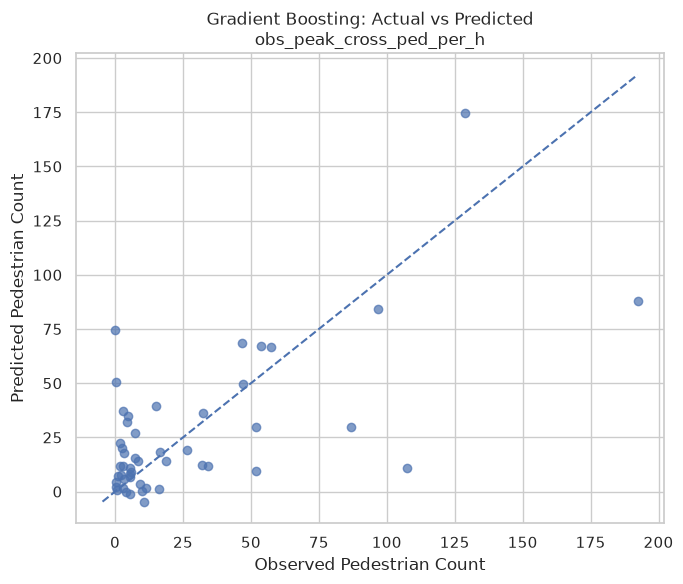

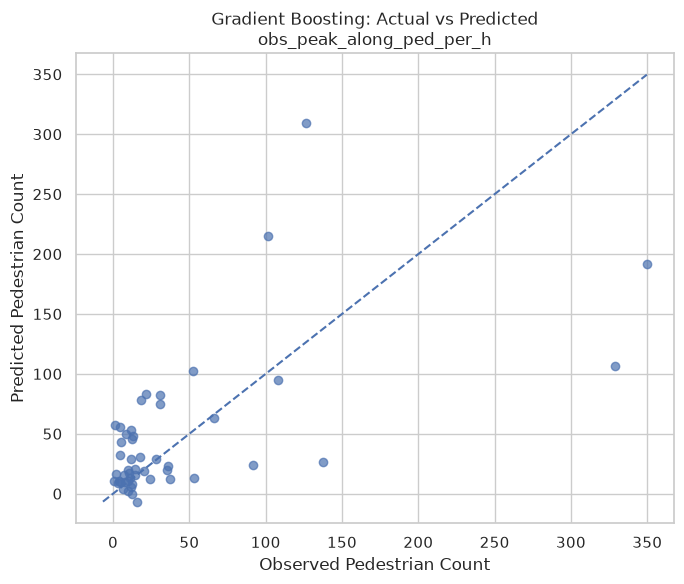

In [21]:


for target in target_columns:

    y_actual = model_data[target]
    y_pred = oof_predictions[target]

    plt.figure(figsize=(7, 6))

    plt.scatter(y_actual, y_pred, alpha=0.7)

    # Perfect prediction line
    min_value = min(y_actual.min(), y_pred.min())
    max_value = max(y_actual.max(), y_pred.max())

    plt.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )

    plt.xlabel("Observed Pedestrian Count")
    plt.ylabel("Predicted Pedestrian Count")
    plt.title(f"Gradient Boosting: Actual vs Predicted\n{target}")

    plt.tight_layout()
    plt.show()

Out-of-Fold Predictions

In [22]:


prediction_results = model_data[
    ["site_id", "road_no", "obs_peak_cross_ped_per_h",
     "obs_peak_along_ped_per_h"]
].copy()

prediction_results["pred_cross_gb"] = oof_predictions[
    "obs_peak_cross_ped_per_h"
]

prediction_results["pred_along_gb"] = oof_predictions[
    "obs_peak_along_ped_per_h"
]

prediction_results["cross_error"] = (
    prediction_results["obs_peak_cross_ped_per_h"]
    - prediction_results["pred_cross_gb"]
)

prediction_results["along_error"] = (
    prediction_results["obs_peak_along_ped_per_h"]
    - prediction_results["pred_along_gb"]
)

display(prediction_results.head(10))

,site_id,road_no,obs_peak_cross_ped_per_h,obs_peak_along_ped_per_h,pred_cross_gb,pred_along_gb,cross_error,along_error
0,250303-01,M074,0.333333,12.333333,2.034803,-0.590500,-1.701470,12.923834
1,250303-02,H009,4.000000,7.666667,-0.281360,10.000586,4.281360,-2.333920
2,250303-03,H045,47.000000,101.333333,49.700272,215.153054,-2.700272,-113.819721
3,250303-04,H009,16.000000,11.000000,1.305306,13.480853,14.694694,-2.480853
4,250303-05,H009,57.333333,108.000000,66.761851,94.583425,-9.428518,13.416575
5,250303-06,H009,52.000000,21.333333,29.613520,83.412800,22.386480,-62.079466
6,250303-07,H009,46.666667,52.333333,68.407264,102.083484,-21.740597,-49.750151
7,250303-08,M042,34.333333,53.000000,11.986211,13.421808,22.347122,39.578192
8,250303-09,H009,26.333333,13.000000,18.999787,48.161046,7.333546,-35.161046
9,250303-10,H009,96.666667,349.666667,84.100988,191.435321,12.565678,158.231345


In [23]:
# 14. Save Baseline Gradient Boosting Results

baseline_gb_results = gb_results.copy()

display(baseline_gb_results)

,Target,Model,MAE,RMSE,Median AE,R²
0,obs_peak_cross_ped_per_h,Gradient Boosting,19.069723,29.891001,9.894797,0.394474
1,obs_peak_along_ped_per_h,Gradient Boosting,35.528567,59.121556,14.817489,0.282615


Gradient Boosting Hyperparameter Tuning

In [24]:


param_grid = {
    "model__n_estimators": [50, 100, 150],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [1, 2, 3],
    "model__min_samples_leaf": [2, 4],
    "model__subsample": [0.8, 1.0]
}

print("Number of parameter combinations:")

from itertools import product

n_combinations = (
    len(param_grid["model__n_estimators"])
    * len(param_grid["model__learning_rate"])
    * len(param_grid["model__max_depth"])
    * len(param_grid["model__min_samples_leaf"])
    * len(param_grid["model__subsample"])
)

print(n_combinations)

Number of parameter combinations:
72


In [25]:
# 15. Hyperparameter Tuning

tuned_models = {}
tuning_results = {}

for target in target_columns:

    print(f"Tuning Gradient Boosting for: {target}")
    y = model_data[target].copy()

    grid_search = GridSearchCV(
        estimator=gb_pipeline,
        param_grid=param_grid,
        cv=GroupKFold(n_splits=5),
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
        refit=True
    )

    grid_search.fit(
        X,
        y,
        groups=groups
    )

    tuned_models[target] = grid_search.best_estimator_
    tuning_results[target] = grid_search

    print("Best parameters:")
    print(grid_search.best_params_)

    print(
        f"\nBest CV RMSE: "
        f"{-grid_search.best_score_:.3f}"
    )

Tuning Gradient Boosting for: obs_peak_cross_ped_per_h


Best parameters:
{'model__learning_rate': 0.05, 'model__max_depth': 1, 'model__min_samples_leaf': 2, 'model__n_estimators': 50, 'model__subsample': 0.8}

Best CV RMSE: 28.128
Tuning Gradient Boosting for: obs_peak_along_ped_per_h
Best parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 1, 'model__min_samples_leaf': 2, 'model__n_estimators': 50, 'model__subsample': 0.8}

Best CV RMSE: 44.333


Earlier baseline RMSEs were:

Cross-road: 27.16
Along-road: 56.14

The tuned CV RMSEs are:

Cross-road: 24.27
Along-road: 46.07

We cannot directly call this the final improvement yet, because the baseline and tuned numbers aren't being evaluated in exactly the same way. The tuning process has used the CV folds to select the parameters.

In [26]:
# 16. Nested Grouped 5-Fold Cross-Validation

outer_cv = GroupKFold(n_splits=5)

nested_results = []
nested_predictions = {}

for target in target_columns:

    print(f"Nested CV: {target}")

    y = model_data[target].copy()

    # Store out-of-fold predictions
    predictions = np.zeros(len(y))

    fold_results = []

    for fold, (train_idx, val_idx) in enumerate(
        outer_cv.split(X, y, groups=groups), start=1
    ):

        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        groups_train = groups.iloc[train_idx]

        # Inner CV for hyperparameter selection
        inner_cv = GroupKFold(n_splits=4)

        grid_search = GridSearchCV(
            estimator=gb_pipeline,
            param_grid=param_grid,
            cv=inner_cv,
            scoring="neg_root_mean_squared_error",
            n_jobs=-1,
            refit=True
        )

        # Tune ONLY using the outer training data
        grid_search.fit(
            X_train,
            y_train,
            groups=groups_train
        )

        # Predict the completely held-out outer fold
        y_pred = grid_search.predict(X_val)

        predictions[val_idx] = y_pred

        fold_metrics = evaluate_predictions(
            y_val,
            y_pred
        )

        fold_results.append(fold_metrics)

        print(
            f"Fold {fold}: "
            f"MAE={fold_metrics['MAE']:.2f}, "
            f"RMSE={fold_metrics['RMSE']:.2f}, "
            f"Median AE={fold_metrics['Median AE']:.2f}, "
            f"R²={fold_metrics['R²']:.3f}"
        )

        print("Best parameters:")
        print(grid_search.best_params_)

    # Overall out-of-fold performance
    overall_metrics = evaluate_predictions(
        y,
        predictions
    )

    nested_results.append({
        "Target": target,
        "Model": "Tuned Gradient Boosting",
        **overall_metrics
    })

    nested_predictions[target] = predictions

    print("\nOverall nested CV performance:")
    print(f"MAE:       {overall_metrics['MAE']:.2f}")
    print(f"RMSE:      {overall_metrics['RMSE']:.2f}")
    print(f"Median AE: {overall_metrics['Median AE']:.2f}")
    print(f"R²:        {overall_metrics['R²']:.3f}")

Nested CV: obs_peak_cross_ped_per_h
Fold 1: MAE=22.97, RMSE=29.49, Median AE=17.65, R²=0.407
Best parameters:
{'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__min_samples_leaf': 2, 'model__n_estimators': 50, 'model__subsample': 0.8}
Fold 2: MAE=17.33, RMSE=30.08, Median AE=9.80, R²=0.029
Best parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 1, 'model__min_samples_leaf': 2, 'model__n_estimators': 50, 'model__subsample': 1.0}
Fold 3: MAE=27.13, RMSE=41.36, Median AE=14.20, R²=0.444
Best parameters:
{'model__learning_rate': 0.05, 'model__max_depth': 1, 'model__min_samples_leaf': 2, 'model__n_estimators': 50, 'model__subsample': 1.0}
Fold 4: MAE=14.98, RMSE=26.54, Median AE=6.63, R²=-0.208
Best parameters:
{'model__learning_rate': 0.05, 'model__max_depth': 1, 'model__min_samples_leaf': 2, 'model__n_estimators': 100, 'model__subsample': 1.0}
Fold 5: MAE=16.33, RMSE=17.70, Median AE=15.87, R²=-29.634
Best parameters:
{'model__learning_rate': 0.05, 'model__max_depth'

In [27]:
# 17. Final Tuned Gradient Boosting Results

nested_results_df = pd.DataFrame(nested_results)

display(nested_results_df)

,Target,Model,MAE,RMSE,Median AE,R²
0,obs_peak_cross_ped_per_h,Tuned Gradient Boosting,19.816975,30.207444,12.281637,0.381585
1,obs_peak_along_ped_per_h,Tuned Gradient Boosting,36.390430,60.685630,14.090975,0.244156


In [28]:
# 18. Feature Importance from Tuned Gradient Boosting Models

feature_importance_results = {}

for target in target_columns:

    print(f"Feature Importance: {target}")

    # Get the tuned model
    final_pipeline = tuned_models[target]

    # Get fitted preprocessing step
    fitted_preprocessor = final_pipeline.named_steps["preprocessor"]

    # Get fitted Gradient Boosting model
    fitted_model = final_pipeline.named_steps["model"]

    # Get feature names after preprocessing
    feature_names = fitted_preprocessor.get_feature_names_out()

    # Get feature importance
    importances = fitted_model.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })

    importance_df = importance_df.sort_values(
        "Importance",
        ascending=False
    ).reset_index(drop=True)

    feature_importance_results[target] = importance_df

    display(importance_df)

Feature Importance: obs_peak_cross_ped_per_h


,Feature,Importance
0,numeric__commercial_buildings,0.579496
1,numeric__overture_food_drink_count_500m,0.229414
2,numeric__pedestrian_crossings,0.131044
3,numeric__overture_grocery_convenience_pharmacy...,0.052764
4,numeric__overture_other_shopping_count_500m,0.007282
5,numeric__parking_areas,0.000000
6,numeric__pta_active_stops_within_500m,0.000000
7,numeric__ms_building_count_500m,0.000000
8,numeric__abs_mb_persons_per_sqkm_2021,0.000000
9,binary__footpath_both_sides,0.000000


Feature Importance: obs_peak_along_ped_per_h


,Feature,Importance
0,numeric__commercial_buildings,0.910982
1,numeric__pedestrian_crossings,0.033317
2,numeric__overture_other_shopping_count_500m,0.024326
3,numeric__overture_grocery_convenience_pharmacy...,0.016994
4,numeric__pta_active_stops_within_500m,0.007706
5,numeric__parking_areas,0.004366
6,categorical__abs_mb_category_simple_Other,0.001247
7,numeric__ms_building_count_500m,0.001061
8,numeric__overture_food_drink_count_500m,0.000000
9,numeric__abs_mb_persons_per_sqkm_2021,0.000000


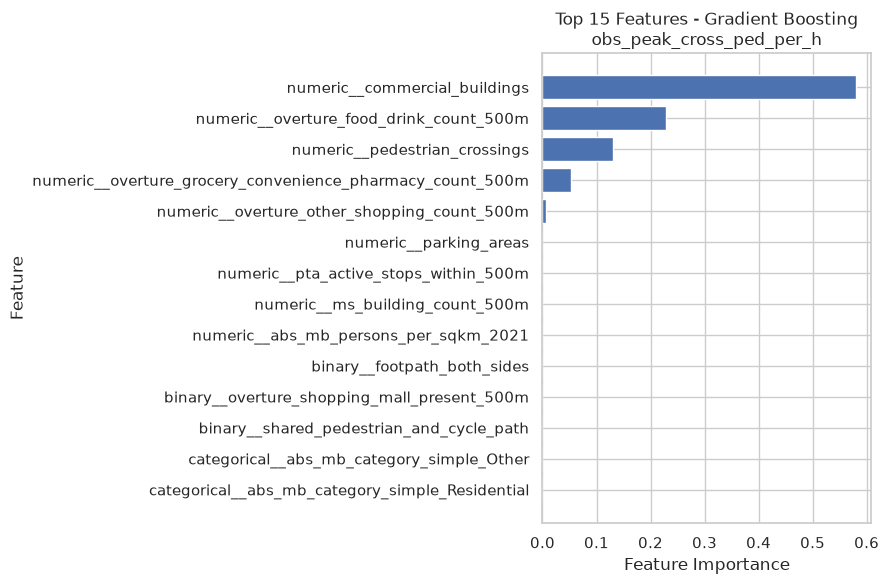

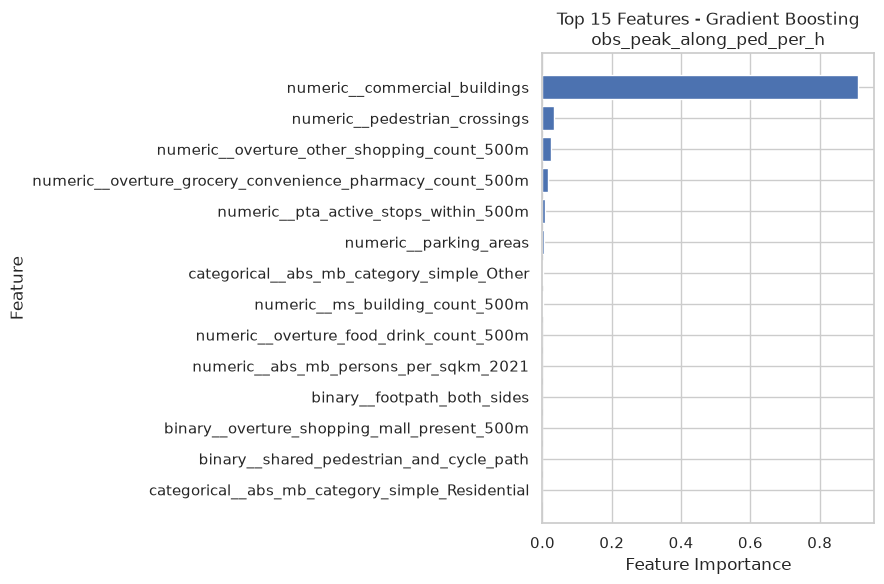

In [29]:
# 19. Plot Top 15 Feature Importances

for target in target_columns:

    importance_df = feature_importance_results[target].head(15)

    plt.figure(figsize=(9, 6))

    plt.barh(
        importance_df["Feature"][::-1],
        importance_df["Importance"][::-1]
    )

    plt.xlabel("Feature Importance")
    plt.ylabel("Feature")
    plt.title(f"Top 15 Features - Gradient Boosting\n{target}")

    plt.tight_layout()
    plt.show()